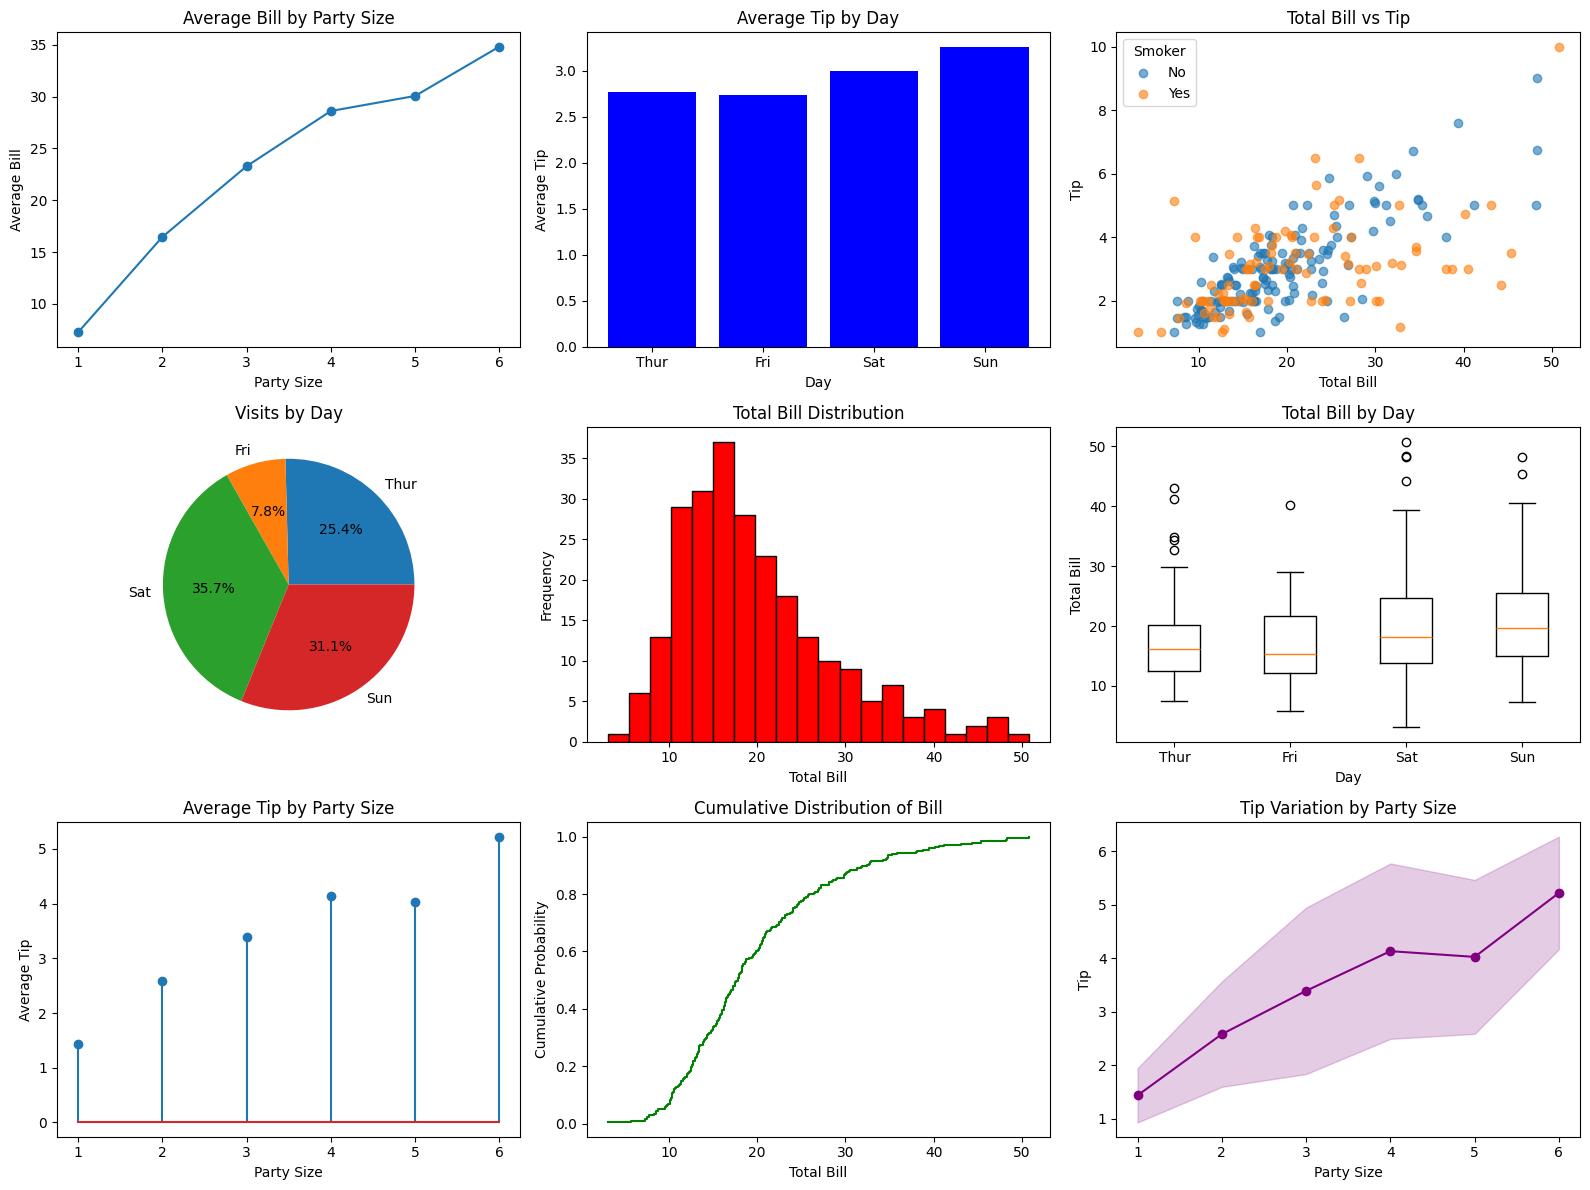

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# Load dataset
df = pd.read_csv("tips.csv")
# Create Figure and 9 Axes
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
# Define category order
day_order = ["Thur", "Fri", "Sat", "Sun"]
# ==========================================
# 1. LINE PLOT
# Average total bill by party size
# ==========================================
avg_bill = df.groupby("size")["total_bill"].mean()
axes[0, 0].plot(
    avg_bill.index,
    avg_bill.values,
    marker="o"
)
axes[0, 0].set_title("Average Bill by Party Size")
axes[0, 0].set_xlabel("Party Size")
axes[0, 0].set_ylabel("Average Bill")
# ==========================================
# 2. BAR PLOT
# Average tip by day
# ==========================================
avg_tip = df.groupby("day")["tip"].mean().reindex(day_order)
axes[0, 1].bar(
    avg_tip.index,
    avg_tip.values,
    color="blue"
)
axes[0, 1].set_title("Average Tip by Day")
axes[0, 1].set_xlabel("Day")
axes[0, 1].set_ylabel("Average Tip")
# ==========================================
# 3. SCATTER PLOT
# Relationship between total bill and tip
# ==========================================
for smoker, group in df.groupby("smoker"):
    axes[0, 2].scatter(
        group["total_bill"],
        group["tip"],
        alpha=0.6,
        label=smoker
    )
axes[0, 2].set_title("Total Bill vs Tip")
axes[0, 2].set_xlabel("Total Bill")
axes[0, 2].set_ylabel("Tip")
axes[0, 2].legend(title="Smoker")
# ==========================================
# 4. PIE CHART
# Percentage of customers by day
# ==========================================
day_counts = df["day"].value_counts().reindex(day_order)
axes[1, 0].pie(
    day_counts,
    labels=day_counts.index,
    autopct="%1.1f%%"
)
axes[1, 0].set_title("Visits by Day")
# ==========================================
# 5. HISTOGRAM
# Distribution of total bill
# ==========================================
axes[1, 1].hist(
    df["total_bill"],
    bins=20,
    color="red",
    edgecolor="black"
)
axes[1, 1].set_title("Total Bill Distribution")
axes[1, 1].set_xlabel("Total Bill")
axes[1, 1].set_ylabel("Frequency")
# ==========================================
# 6. BOX PLOT
# Distribution of total bill by day
# ==========================================
bill_by_day = [
    df.loc[df["day"] == day, "total_bill"]
    for day in day_order
]
axes[1, 2].boxplot(
    bill_by_day,
    tick_labels=day_order
)
axes[1, 2].set_title("Total Bill by Day")
axes[1, 2].set_xlabel("Day")
axes[1, 2].set_ylabel("Total Bill")
# ==========================================
# 7. STEM PLOT
# Average tip by party size
# ==========================================
avg_tip_by_size = df.groupby("size")["tip"].mean()
axes[2, 0].stem(
    avg_tip_by_size.index,
    avg_tip_by_size.values
)
axes[2, 0].set_title("Average Tip by Party Size")
axes[2, 0].set_xlabel("Party Size")
axes[2, 0].set_ylabel("Average Tip")
# ==========================================
# 8. STEP PLOT
# Cumulative distribution of total bill
# ==========================================
sorted_bill = np.sort(df["total_bill"].values)
cumulative_probability = (
    np.arange(1, len(sorted_bill) + 1) / len(sorted_bill)
)
axes[2, 1].step(
    sorted_bill,
    cumulative_probability,
    where="post",
    color="green"
)
axes[2, 1].set_title("Cumulative Distribution of Bill")
axes[2, 1].set_xlabel("Total Bill")
axes[2, 1].set_ylabel("Cumulative Probability")
# ==========================================
# 9. FILL BETWEEN
# Average tip and standard deviation
# ==========================================
stats = df.groupby("size")["tip"].agg(["mean", "std"])
x = stats.index
mean = stats["mean"]
std = stats["std"].fillna(0)
axes[2, 2].plot(
    x,
    mean,
    color="purple",
    marker="o"
)
axes[2, 2].fill_between(
    x,
    np.maximum(mean - std, 0),
    mean + std,
    alpha=0.2,
    color="purple"
)
axes[2, 2].set_title("Tip Variation by Party Size")
axes[2, 2].set_xlabel("Party Size")
axes[2, 2].set_ylabel("Tip")
# ==========================================
# FINAL CONFIGURATION
# =====================
fig.tight_layout()

plt.show()